<a href="https://colab.research.google.com/github/Vachana7/4IK25CS228_DAV_LAB/blob/main/4IK25CS228_EXP_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [7]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df=df[["Fare","Pclass","Age","SibSp","Parch"]]
df['Age']=df['Age'].fillna(df['Age'].mean())
df['SibSp']=df['SibSp'].fillna(df['SibSp'].mean())
df['Parch']=df['Parch'].fillna(df['Parch'].mean())
df

,Fare,Pclass,Age,SibSp,Parch
0,7.2500,3,22.000000,1,0
1,71.2833,1,38.000000,1,0
2,7.9250,3,26.000000,0,0
3,53.1000,1,35.000000,1,0
4,8.0500,3,35.000000,0,0
...,...,...,...,...,...
886,13.0000,2,27.000000,0,0
887,30.0000,1,19.000000,0,0
888,23.4500,3,29.699118,1,2
889,30.0000,1,26.000000,0,0


In [8]:
X_simple=df[['Pclass']]
y=df['Fare']
X_tr,X_te,y_tr,y_te=train_test_split(X_simple,y,test_size=0.2,random_state=42)
model_simple=LinearRegression().fit(X_tr,y_tr)
pred_simple=model_simple.predict(X_te)
print("SIMPLE Regression -- Intercept:",round(model_simple.intercept_,2))
print("SIMPLE Regression -- Slope:",round(model_simple.coef_[0],2))
print("SIMPLE Regression -- R2:",round(r2_score(y_te,pred_simple),3))
print("SIMPLE Regression -- RMSE:",round(np.sqrt(mean_squared_error(y_te,pred_simple)),2))

SIMPLE Regression -- Intercept: 112.88
SIMPLE Regression -- Slope: -34.46
SIMPLE Regression -- R2: 0.31
SIMPLE Regression -- RMSE: 32.68


In [9]:
X_multi=df[['Pclass','Age','SibSp','Parch']]
X_tr2,X_te2,y_tr2,y_te2=train_test_split(X_multi,y,test_size=0.2,random_state=42)
model_multi=LinearRegression().fit(X_tr2,y_tr2)
pred_multi=model_multi.predict(X_te2)
print("MULTIPLE Regression -- Intercept:",round(model_multi.intercept_,2))
for name,coef in zip(X_multi.columns,model_multi.coef_):
    print(f"MULTIPLE Regression -- Coefficient of {name}:",round(coef,2))
print("MULTIPLE Regression -- R2:",round(r2_score(y_te2,pred_multi),3))
print("MULTIPLE Regression -- RMSE:",round(np.sqrt(mean_squared_error(y_te2,pred_multi)),2))

MULTIPLE Regression -- Intercept: 113.75
MULTIPLE Regression -- Coefficient of Pclass: -36.0
MULTIPLE Regression -- Coefficient of Age: -0.15
MULTIPLE Regression -- Coefficient of SibSp: 5.26
MULTIPLE Regression -- Coefficient of Parch: 11.14
MULTIPLE Regression -- R2: 0.388
MULTIPLE Regression -- RMSE: 30.78


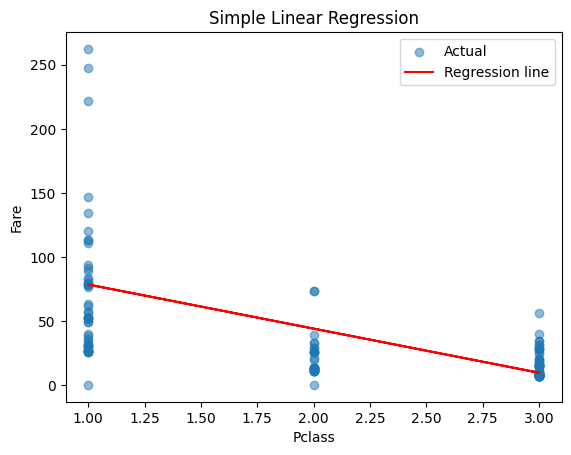

In [11]:
plt.scatter(X_te, y_te, alpha=0.5, label='Actual')
plt.plot(X_te, pred_simple, color='red', label='Regression line')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

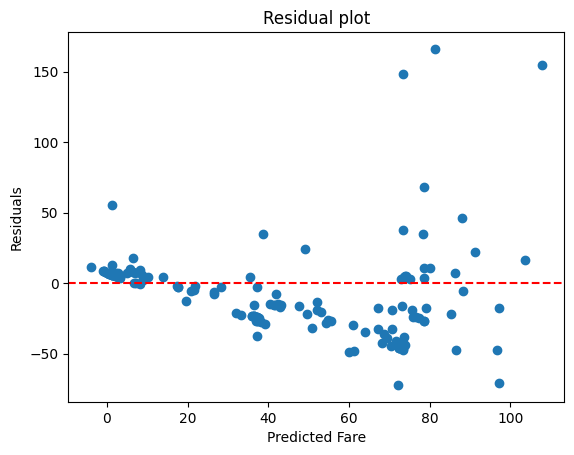

In [12]:
residuals = y_te2 - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Fare'); plt.ylabel('Residuals');plt.title('Residual plot')
plt.show()

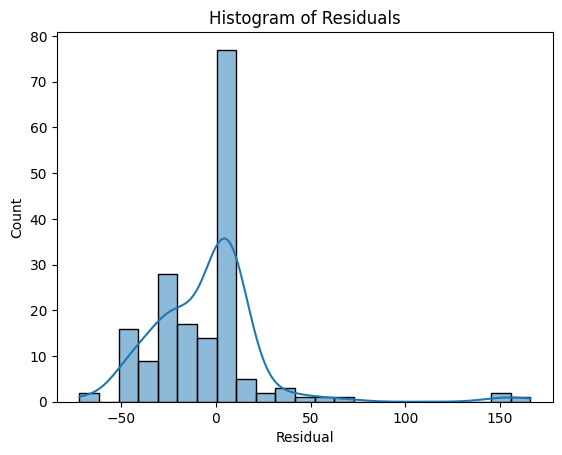

In [15]:
sns.histplot(residuals, kde=True)
plt.xlabel('Residual');plt.title('Histogram of Residuals')
plt.show()

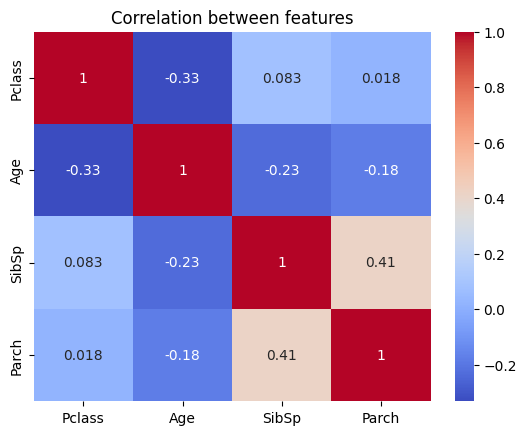

In [17]:
sns.heatmap(X_multi.corr(),annot=True, cmap='coolwarm')
plt.title('Correlation between features')
plt.show()